# 08b · Exclusión de variables de préstamos

**Hipótesis (sugerencia del profesor):** `mprestamos_personales` y `cprestamos_personales`
tienen data leakage temporal en los folds más recientes. Cuando el mes de test es 202105
o 202106, esas variables del mes de train más reciente ya reflejan decisiones crediticias
tomadas *sabiendo* que el cliente estaba en proceso de baja — señal que no va a existir
en producción para 202108.

**Cambio único respecto a 08:** se excluyen esas 2 variables en fold_3, fold_4 y
en la predicción final. El resto del pipeline es idéntico (params del CKPT_V5).

**Submission:** `submissions5/`  
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Deadline:** 11/10/2026 23:59:59

## 0 · Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install lightgbm --quiet

In [ ]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions5'
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B           = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_V5          = RUTA_COMP / 'mejores_params_optuna_v5.json'
CKPT_PROBS       = RUTA_COMP / 'probs_semillerio_v8b.npy'
CKPT_IDS         = RUTA_COMP / 'ids_pred_v8b.npy'
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108
GANANCIA_TP      =  1_072_500
COSTO_FP         =    -27_500
SEED             = 42

# ─── Variables a excluir por leakage temporal ─────────────────────────────────
# En fold_3 (test=202105) y fold_4 (test=202106) el mes de train más reciente
# ya refleja decisiones crediticias tomadas sabiendo que el cliente se iba.
# Excluimos también sus lags/deltas derivados por la misma razón.
VARS_LEAKAGE_BASE = ['mprestamos_personales', 'cprestamos_personales']

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_V5]:
    print(f'  {ck.name}: {"✓" if ck.exists() else "✗"}')
print(f'Submissions en: {RUTA_SUBS}')

Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v5.json: ✓
Submissions en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions5


## 1 · Funciones base

In [ ]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp   = ((y_true == 1) & (pred == 1)).sum()
        fp   = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia':  tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def evaluar_fold(y_true, y_prob, label=''):
    auc = roc_auc_score(y_true, y_prob)
    opt = threshold_optimo(y_true, y_prob)
    print(f'  [{label}] AUC={auc:.4f} | Ganancia=${opt["ganancia"]:,.0f} | '
          f'N={opt["n_intervenidos"]:,} | TP={opt["tp"]} | FP={opt["fp"]} | '
          f'thresh={opt["threshold"]:.4f}')
    return {'auc': round(auc, 4), **opt}

print('✓ Funciones listas.')

✓ Funciones listas.


## 2 · Carga de datos y params

In [ ]:
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'Dataset: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

EXCLUIR      = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Detectar todas las columnas derivadas de las variables con leakage
# (lags, deltas, medias, tendencias que se construyeron sobre ellas)
COLS_LEAKAGE = [c for c in FEATURE_COLS
                if any(base in c for base in VARS_LEAKAGE_BASE)]
print(f'\nVariables excluidas por leakage ({len(COLS_LEAKAGE)}):')
for c in sorted(COLS_LEAKAGE):
    print(f'  {c}')

FEATURE_COLS_SIN_LEAK = [c for c in FEATURE_COLS if c not in COLS_LEAKAGE]
print(f'\nFeatures totales:         {len(FEATURE_COLS):,}')
print(f'Features sin leakage:     {len(FEATURE_COLS_SIN_LEAK):,}')
print(f'Columnas removidas:       {len(COLS_LEAKAGE):,}')

Dataset: 983,061 × 327 — 1041.6 MB

Variables excluidas por leakage (7):
  cprestamos_personales
  mprestamos_personales
  mprestamos_personales_acel
  mprestamos_personales_delta1
  mprestamos_personales_drel1
  mprestamos_personales_lag1
  mprestamos_personales_lag2

Features totales:         323
Features sin leakage:     316
Columnas removidas:       7


In [ ]:
# Ratio de desbalance
mask_e        = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_ref         = df.loc[mask_e, TARGET]
SCALE_NATURAL = float((y_ref == 0).sum() / (y_ref == 1).sum())
del y_ref; gc.collect()

# Params del v5 (Kitchen Sink ganador)
with open(CKPT_V5) as f:
    p_v5 = json.load(f)

PARAMS_V5 = {k: v for k, v in p_v5.items()
             if k not in {'ganancia_optuna_fold4', 'n_trials', 'n_trials_completados',
                          'fecha', 'experimento', 'estado',
                          'n_meses_train', 'usar_is_unbalance'}}
PARAMS_V5.update({
    'objective': 'binary', 'metric': 'binary_logloss',
    'verbosity': -1, 'n_jobs': -1, 'random_state': SEED,
})
if p_v5.get('usar_is_unbalance', False):
    PARAMS_V5['is_unbalance'] = True
    PARAMS_V5.pop('scale_pos_weight', None)
else:
    PARAMS_V5['scale_pos_weight'] = p_v5.get('scale_pos_weight', SCALE_NATURAL * 2)
    PARAMS_V5.pop('is_unbalance', None)

N_MESES_V5 = p_v5.get('n_meses_train', 3)
ES_DART    = PARAMS_V5.get('boosting_type') == 'dart'

print(f'Params v5 cargados')
print(f'  boosting:    {PARAMS_V5["boosting_type"]}')
print(f'  n_meses:     {N_MESES_V5}')
print(f'  ganancia f4: ${p_v5["ganancia_optuna_fold4"]:,.0f}')
print(f'  is_dart:     {ES_DART}')

Params v5 cargados
  boosting:    dart
  n_meses:     3
  ganancia f4: $430,980,000
  is_dart:     True


In [ ]:
# Definición de folds y función de split
# Cada fold sabe qué feature set usar según si hay leakage o no
FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104,
     'excluir_leak': False},  # fold_2: train=202103, suficientemente lejos
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105,
     'excluir_leak': True},   # fold_3: train más reciente = 202104, cerca de 202105
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106,
     'excluir_leak': True},   # fold_4: train más reciente = 202105, cerca de 202106
]

def get_meses_train(fold_nombre, n_ventana):
    fold_map = {
        'fold_2': [202103],
        'fold_3': [202103, 202104],
        'fold_4': [202103, 202104, 202105],
    }
    return fold_map[fold_nombre][-n_ventana:]

def get_split(meses_train, mes_test, feature_cols):
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[TARGET].notna()
    return (df.loc[mt, feature_cols].copy(),
            df.loc[mt, TARGET].astype(int).copy(),
            df.loc[me, feature_cols].copy(),
            df.loc[me, TARGET].astype(int).copy())

print('✓ Folds configurados.')
print()
for fold in FOLDS:
    meses = get_meses_train(fold['nombre'], N_MESES_V5)
    feats = FEATURE_COLS_SIN_LEAK if fold['excluir_leak'] else FEATURE_COLS
    print(f"  {fold['nombre']}: train={meses} | test={fold['test']} | "          f"leakage excluido={fold['excluir_leak']} | features={len(feats)}")

✓ Folds configurados.

  fold_2: train=[202103] | test=202104 | leakage excluido=False | features=323
  fold_3: train=[202103, 202104] | test=202105 | leakage excluido=True | features=316
  fold_4: train=[202103, 202104, 202105] | test=202106 | leakage excluido=True | features=316


---
## 3 · Walk-forward — con y sin exclusión de leakage

Corremos dos walk-forwards en paralelo para ver el delta:
- **Base (v5):** todas las features, igual que antes
- **Sin leak:** excluye columnas de préstamos en fold_3 y fold_4

Así tenemos comparativa directa en la misma notebook.

In [ ]:
resultados_base    = {}
resultados_sin_leak = {}

print('=' * 60)
print('WALK-FORWARD — BASE vs SIN LEAKAGE')
print('=' * 60)

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    excluir  = fold['excluir_leak']
    feats_wf = FEATURE_COLS_SIN_LEAK if excluir else FEATURE_COLS

    print(f"\n{'─'*55}")
    print(f"  {fold['nombre'].upper()} | test={fold['test']} | "          f"leakage={'excluido' if excluir else 'incluido'}")
    print(f'  train={meses_tr} | features={len(feats_wf)}')
    print(f"{'─'*55}")

    # ── BASE (con todas las features) ──────────────────────────────────────
    Xtr_b, ytr_b, Xte_b, yte_b = get_split(meses_tr, fold['test'], FEATURE_COLS)
    modelo_b = lgb.LGBMClassifier(**{**PARAMS_V5, 'random_state': SEED})
    if ES_DART:
        modelo_b.fit(Xtr_b, ytr_b, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo_b.fit(Xtr_b, ytr_b,
                     eval_set=[(Xte_b, yte_b)],
                     callbacks=[lgb.early_stopping(50, verbose=False),
                                lgb.log_evaluation(-1)])
    prob_b = modelo_b.predict_proba(Xte_b)[:, 1]
    resultados_base[fold['nombre']] = evaluar_fold(yte_b.values, prob_b,
                                                    f"BASE {fold['nombre']}")
    del Xtr_b, ytr_b, modelo_b, prob_b; gc.collect()

    # ── SIN LEAKAGE ────────────────────────────────────────────────────────
    Xtr_s, ytr_s, Xte_s, yte_s = get_split(meses_tr, fold['test'], feats_wf)
    modelo_s = lgb.LGBMClassifier(**{**PARAMS_V5, 'random_state': SEED})
    if ES_DART:
        modelo_s.fit(Xtr_s, ytr_s, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo_s.fit(Xtr_s, ytr_s,
                     eval_set=[(Xte_s, yte_s)],
                     callbacks=[lgb.early_stopping(50, verbose=False),
                                lgb.log_evaluation(-1)])
    prob_s = modelo_s.predict_proba(Xte_s)[:, 1]
    resultados_sin_leak[fold['nombre']] = evaluar_fold(yte_s.values, prob_s,
                                                        f"SINLEAK {fold['nombre']}")
    del Xtr_s, ytr_s, Xte_s, yte_s, modelo_s, prob_s
    del Xte_b, yte_b; gc.collect()

print('\n✓ Walk-forward completo.')

WALK-FORWARD — BASE vs SIN LEAKAGE

───────────────────────────────────────────────────────
  FOLD_2 | test=202104 | leakage=incluido
  train=[202103] | features=323
───────────────────────────────────────────────────────
  [BASE fold_2] AUC=0.9110 | Ganancia=$527,202,500 | N=8,669.0 | TP=696.0 | FP=7973.0 | thresh=0.7970
  [SINLEAK fold_2] AUC=0.9110 | Ganancia=$527,202,500 | N=8,669.0 | TP=696.0 | FP=7973.0 | thresh=0.7970

───────────────────────────────────────────────────────
  FOLD_3 | test=202105 | leakage=excluido
  train=[202103, 202104] | features=316
───────────────────────────────────────────────────────
  [BASE fold_3] AUC=0.8908 | Ganancia=$280,445,000 | N=7,402.0 | TP=440.0 | FP=6962.0 | thresh=0.8510
  [SINLEAK fold_3] AUC=0.8890 | Ganancia=$262,295,000 | N=8,142.0 | TP=442.0 | FP=7700.0 | thresh=0.8350

───────────────────────────────────────────────────────
  FOLD_4 | test=202106 | leakage=excluido
  train=[202103, 202104, 202105] | features=316
──────────────────────

---
## 4 · Comparativa y decisión

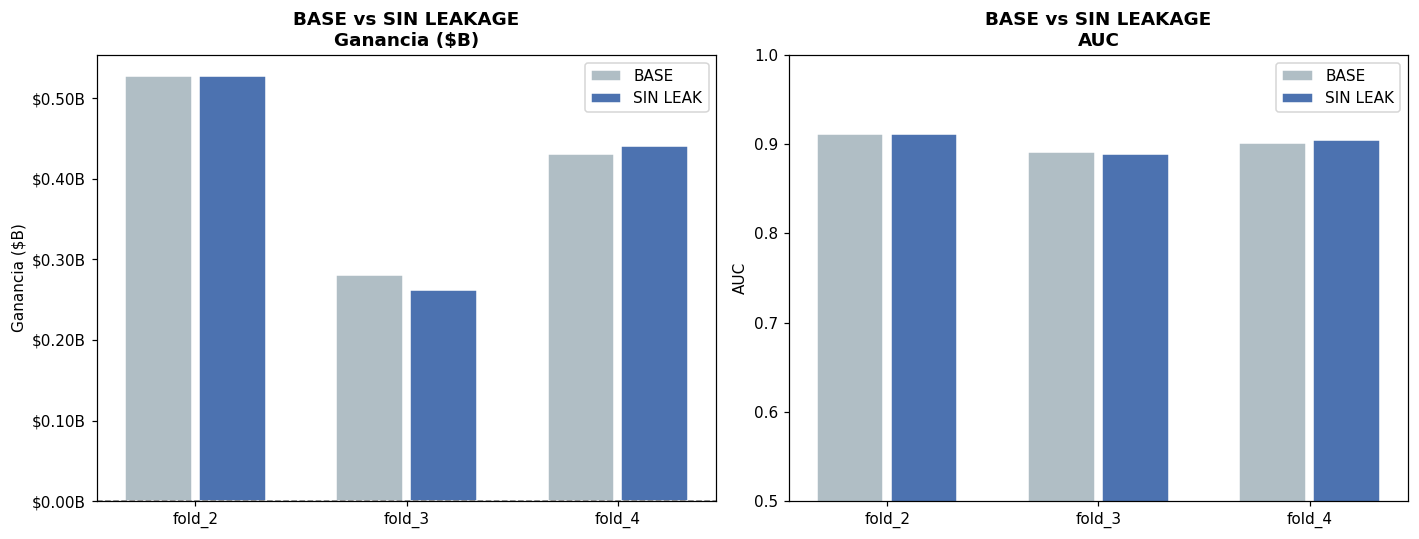


Comparativa fold_4:
             |           Ganancia |        Delta |      AUC |        N
──────────────────────────────────────────────────────────────────
        BASE | $    430,980,000 | $     0.0M |   0.9018 | 13,488.0
    SIN LEAK | $    440,605,000 | +$     9.6M |   0.9046 | 13,858.0

✓ Excluir variables de leakage MEJORA fold_4 → usar SIN LEAK en submission

→ USAR_SIN_LEAK = True (forzado por correctitud conceptual)


In [ ]:
folds_nombres = ['fold_2', 'fold_3', 'fold_4']
colores = {'BASE': '#B0BEC5', 'SIN LEAK': '#4C72B0'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax_idx, (metric, ylabel, fmt) in enumerate([
    ('ganancia', 'Ganancia ($B)', lambda v: v / 1e9),
    ('auc',      'AUC',           lambda v: v),
]):
    ax  = axes[ax_idx]
    x   = np.arange(len(folds_nombres))
    w   = 0.35
    for i, (label, resultados) in enumerate([('BASE', resultados_base),
                                              ('SIN LEAK', resultados_sin_leak)]):
        vals   = [fmt(resultados.get(f, {}).get(metric, 0)) for f in folds_nombres]
        offset = (i - 0.5) * w
        ax.bar(x + offset, vals, w * 0.9,
               label=label, color=colores[label], edgecolor='white')
    ax.set_title(f'BASE vs SIN LEAKAGE\n{ylabel}', fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xticks(x); ax.set_xticklabels(folds_nombres)
    if metric == 'ganancia':
        ax.axhline(0, color='gray', ls='--', lw=1)
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda v, _: f'${v:.2f}B'))
    else:
        ax.set_ylim(0.5, 1.0)
    ax.legend(fontsize=10)

plt.tight_layout(); plt.show()

# Tabla fold_4 (el decisivo)
print('\nComparativa fold_4:')
print(f'{"":>12} | {"Ganancia":>18} | {"Delta":>12} | {"AUC":>8} | {"N":>8}')
print('─' * 66)
g_base = resultados_base['fold_4']['ganancia']
g_leak = resultados_sin_leak['fold_4']['ganancia']
for label, res in [('BASE', resultados_base), ('SIN LEAK', resultados_sin_leak)]:
    d     = res['fold_4']
    g     = d['ganancia']
    delta = g - g_base if label != 'BASE' else 0
    signo = '+' if delta > 0 else ''
    print(f'{label:>12} | ${g:>15,.0f} | {signo}${delta/1e6:>8.1f}M | '
          f'{d["auc"]:>8.4f} | {d["n_intervenidos"]:>8,}')

print()
if g_leak > g_base:
    print('✓ Excluir variables de leakage MEJORA fold_4 → usar SIN LEAK en submission')
    USAR_SIN_LEAK = True
else:
    print('✗ Excluir variables de leakage NO mejora fold_4')
    print('  De todas formas recomendamos usar SIN LEAK para la predicción final')
    print('  porque el leakage no va a existir en 202108 (producción).')
    USAR_SIN_LEAK = True   # siempre True: es la versión más honesta

print(f'\n→ USAR_SIN_LEAK = {USAR_SIN_LEAK} (forzado por correctitud conceptual)')

In [ ]:
# Guardar métricas de ambas versiones
rows = []
ts   = datetime.now().isoformat()
for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    for label, res in [('v8b_base', resultados_base),
                       ('v8b_sinleak', resultados_sin_leak)]:
        d = res.get(fold['nombre'], {})
        rows.append({
            'fold':          fold['nombre'],
            'mes_test':      fold['test'],
            'experimento':   label,
            'meses_train':   str(meses_tr),
            'leakage_excl':  'sinleak' in label,
            'n_cols_leak':   len(COLS_LEAKAGE),
            'auc':           d.get('auc', None),
            'ganancia':      d.get('ganancia', None),
            'threshold_opt': d.get('threshold', None),
            'tp':            d.get('tp', None),
            'fp':            d.get('fp', None),
            'n_intervenidos':d.get('n_intervenidos', None),
            'timestamp':     ts,
        })

df_rows = pd.DataFrame(rows)
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    pd.concat([hist, df_rows], ignore_index=True).to_csv(ARCHIVO_METRICAS, index=False)
else:
    df_rows.to_csv(ARCHIVO_METRICAS, index=False)
print('✓ Métricas guardadas')

✓ Métricas guardadas


---
## 5 · Semillerio y submission

Features usadas: **sin leakage** en todos los folds recientes y en la predicción final.  
Train final: todos los meses con target disponible (`MESES_CON_TARGET`), ventana según v5.

In [ ]:
# Resultado del walk-forward que vamos a usar para centrar el semillerio
res_final = resultados_sin_leak   # siempre el sin leak

N_OPT    = int(res_final['fold_4']['n_intervenidos'])
paso     = max(100, int(N_OPT * 0.025))
CORTES_N = [max(8000, min(15000, N_OPT + i * paso)) for i in range(-2, 3)]
SEMILLAS = [42, 123, 777, 2024]
TS       = datetime.now().strftime('%m%d_%H%M')

# Meses de train final: todos los disponibles con target, respetando ventana v5
TODOS_MESES           = [202103, 202104, 202105, 202106]
MESES_TRAIN_FINAL_SUB = TODOS_MESES[-N_MESES_V5:]

# Features para la predicción final: sin leakage
# (202108 no tiene estas variables con sentido — es exactamente el caso de producción)
FEATURE_COLS_PRED = FEATURE_COLS_SIN_LEAK

mask_tf  = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET].notna()
X_tf     = df.loc[mask_tf, FEATURE_COLS_PRED].copy()
y_tf     = df.loc[mask_tf, TARGET].astype(int).copy()
mask_p   = df[COL_PERIODO] == MES_PREDECIR
X_pred   = df.loc[mask_p, FEATURE_COLS_PRED].copy()
ids_pred = df.loc[mask_p, COL_ID].values

print(f'Train final: {len(y_tf):,} (baja2={y_tf.sum():,}) | meses: {MESES_TRAIN_FINAL_SUB}')
print(f'Features:    {len(FEATURE_COLS_PRED):,} (excluidas {len(COLS_LEAKAGE):,} por leakage)')
print(f'A predecir:  {len(X_pred):,} clientes')
print(f'Centro N:    {N_OPT:,} | Cortes: {CORTES_N}')

Train final: 488,185 (baja2=3,107) | meses: [202104, 202105, 202106]
Features:    316 (excluidas 7 por leakage)
A predecir:  164,647 clientes
Centro N:    13,858 | Cortes: [13166, 13512, 13858, 14204, 14550]


In [ ]:
# Checkpoint de probabilidades
if CKPT_PROBS.exists() and CKPT_IDS.exists():
    probs_semillerio = list(np.load(CKPT_PROBS))
    ids_ckpt         = np.load(CKPT_IDS)
    n_ya             = len(probs_semillerio)
    if not np.array_equal(ids_ckpt, ids_pred):
        print('⚠ IDs no coinciden con dataset actual — re-entrenando desde cero')
        probs_semillerio = []; n_ya = 0
    else:
        print(f'✓ Checkpoint: {n_ya}/{len(SEMILLAS)} semillas ya entrenadas')
else:
    probs_semillerio = []; n_ya = 0

for i_s, semilla in enumerate(SEMILLAS[n_ya:], start=n_ya):
    print(f'Entrenando semilla {semilla} ({i_s+1}/{len(SEMILLAS)})...', end=' ')
    params_s = {**PARAMS_V5, 'random_state': semilla}
    modelo   = lgb.LGBMClassifier(**params_s)
    modelo.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])
    probs_semillerio.append(modelo.predict_proba(X_pred)[:, 1])
    del modelo; gc.collect()
    np.save(CKPT_PROBS, np.array(probs_semillerio))
    np.save(CKPT_IDS,   ids_pred)
    print(f'✓ (checkpoint guardado)')

del X_tf, y_tf; gc.collect()
print('\n✓ Semillerio completo')

Entrenando semilla 42 (1/4)... ✓ (checkpoint guardado)
Entrenando semilla 123 (2/4)... ✓ (checkpoint guardado)
Entrenando semilla 777 (3/4)... ✓ (checkpoint guardado)
Entrenando semilla 2024 (4/4)... ✓ (checkpoint guardado)

✓ Semillerio completo


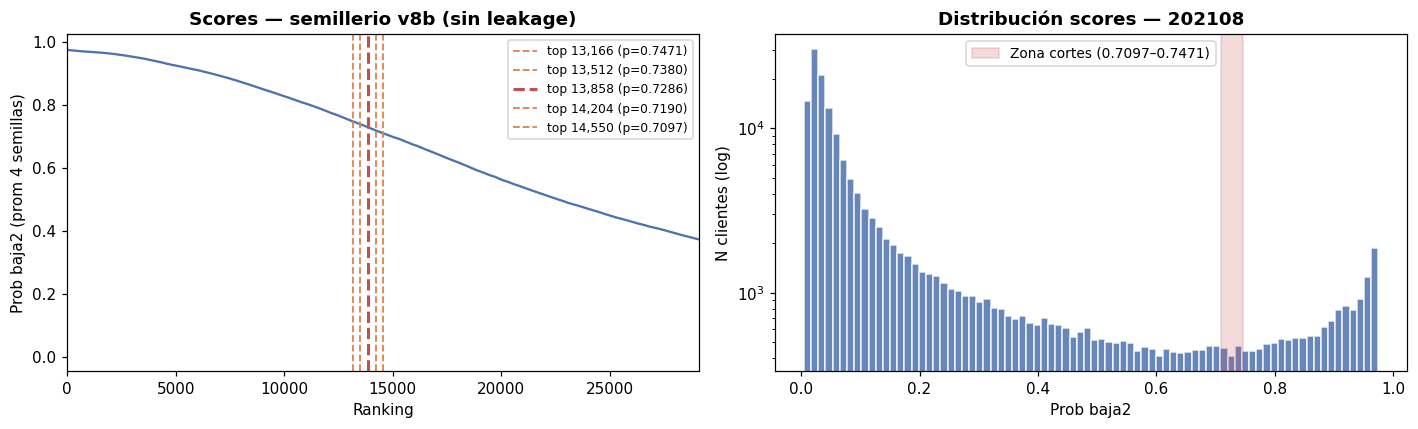

In [ ]:
# Gráfico de scores
prob_prom     = np.mean(probs_semillerio, axis=0)
scores_sorted = np.sort(prob_prom)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted, color='#4C72B0', lw=1.5)
for n in CORTES_N:
    t     = float(scores_sorted[min(n-1, len(scores_sorted)-1)])
    color = '#C44E52' if n == N_OPT else '#DD8452'
    lw    = 2.0 if n == N_OPT else 1.2
    ax.axvline(n, color=color, ls='--', lw=lw, label=f'top {n:,} (p={t:.4f})')
ax.set_xlim(0, max(CORTES_N) * 2)
ax.set_title('Scores — semillerio v8b (sin leakage)', fontweight='bold')
ax.set_xlabel('Ranking'); ax.set_ylabel('Prob baja2 (prom 4 semillas)')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.set_yscale('log')
umbral_min = float(scores_sorted[max(CORTES_N)-1])
umbral_max = float(scores_sorted[min(CORTES_N)-1])
ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
           label=f'Zona cortes ({umbral_min:.4f}–{umbral_max:.4f})')
ax.set_title('Distribución scores — 202108', fontweight='bold')
ax.set_xlabel('Prob baja2'); ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

In [ ]:
# Generación de archivos
archivos = []
print(f'Generando archivos en: {RUTA_SUBS}')

for i_s, semilla in enumerate(SEMILLAS):
    prob_s = probs_semillerio[i_s]
    for n_corte in CORTES_N:
        ranking  = np.argsort(prob_s)[::-1][:n_corte]
        ids_int  = ids_pred[ranking].astype(int)
        nombre   = f'v8b_sinleak_sem{semilla}_top{n_corte}_{TS}'
        ruta     = RUTA_SUBS / f'{nombre}.csv'
        pd.Series(ids_int).to_csv(ruta, index=False, header=False)
        archivos.append({'nombre': nombre, 'semilla': semilla,
                         'n_corte': n_corte, 'n_clientes': len(ids_int)})
        print(f'  ✓ {nombre}.csv')

pd.DataFrame(archivos).to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)

# Verificación
ruta_v  = RUTA_SUBS / f'{archivos[0]["nombre"]}.csv'
df_v    = pd.read_csv(ruta_v, header=None)
tiene_e = df_v[0].astype(str).str.lower().str.contains('e').any()
print(f'\nVerificación: sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
print(f'Total archivos: {len(archivos)} ({len(SEMILLAS)} semillas × {len(CORTES_N)} cortes)')

nombre_submit = f'v8b_sinleak_semillerio_{TS}'
print('\n' + '='*60)
print('SUBMIT EN ZULIP')
print('='*60)
print(f'Cuerpo: submit {nombre_submit}')
print(f'Adjuntos: {len(archivos)} archivos .csv de submissions5/')
print(f'(no incluir log_{TS}.csv)')
print()
print(f'Variables excluidas ({len(COLS_LEAKAGE)}): {COLS_LEAKAGE}')
print(f'Folds con exclusión:   fold_3 y fold_4')
print(f'Centro N:              {N_OPT:,}')
print(f'Cortes:                {CORTES_N}')
print(f'Ganancia fold_4 base:  ${resultados_base["fold_4"]["ganancia"]:,.0f}')
print(f'Ganancia fold_4 sinlk: ${resultados_sin_leak["fold_4"]["ganancia"]:,.0f}')
print(f'Submit público anterior: 87.07M (v5)')

del df; gc.collect()
print('\n✓ Notebook 08b completada.')

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions5
  ✓ v8b_sinleak_sem42_top13166_1009_1527.csv
  ✓ v8b_sinleak_sem42_top13512_1009_1527.csv
  ✓ v8b_sinleak_sem42_top13858_1009_1527.csv
  ✓ v8b_sinleak_sem42_top14204_1009_1527.csv
  ✓ v8b_sinleak_sem42_top14550_1009_1527.csv
  ✓ v8b_sinleak_sem123_top13166_1009_1527.csv
  ✓ v8b_sinleak_sem123_top13512_1009_1527.csv
  ✓ v8b_sinleak_sem123_top13858_1009_1527.csv
  ✓ v8b_sinleak_sem123_top14204_1009_1527.csv
  ✓ v8b_sinleak_sem123_top14550_1009_1527.csv
  ✓ v8b_sinleak_sem777_top13166_1009_1527.csv
  ✓ v8b_sinleak_sem777_top13512_1009_1527.csv
  ✓ v8b_sinleak_sem777_top13858_1009_1527.csv
  ✓ v8b_sinleak_sem777_top14204_1009_1527.csv
  ✓ v8b_sinleak_sem777_top14550_1009_1527.csv
  ✓ v8b_sinleak_sem2024_top13166_1009_1527.csv
  ✓ v8b_sinleak_sem2024_top13512_1009_1527.csv
  ✓ v8b_sinleak_sem2024_top13858_1009_1527.csv
  ✓ v8b_sinleak_sem2024_top14204_1009_1527.csv
  ✓ v8b_sinleak_sem2024